# MCC Stage A: Sentence-Level Argument Mining Results

This notebook visualizes the results of the first stage of the MCC (Mean Correlation Coefficient) pipeline - Sentence-Level Argument Mining using BERT-based classification.

In [5]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics import confusion_matrix, classification_report, matthews_corrcoef
from datetime import datetime

# Set style for visualizations
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

In [ ]:
# Load the results from the trace outputs
results_path = Path('../src/outputs/trace/results.json')
trace_report_path = Path('../src/outputs/trace/trace_report.json')

with open(results_path, 'r') as f:
    results = json.load(f)

with open(trace_report_path, 'r') as f:
    trace_report = json.load(f)

print("✓ Results loaded successfully")
print(f"Pipeline executed: {trace_report['pipeline_start']} - {trace_report['pipeline_end']}")
print(f"Total duration: {trace_report['total_elapsed_seconds']:.2f} seconds")

## Load Results Data

In [ ]:
# SVM Results
svm_results = results.get('svm', {})
print("\n" + "=" * 60)
print("SVM RESULTS")
print("=" * 60)
print(f"Training F1 Score: {svm_results.get('train_f1', 'N/A'):.4f}")
print(f"Test F1 Score: {svm_results.get('test_f1', 'N/A'):.4f}")
print(f"Test Accuracy: {svm_results.get('test_accuracy', 'N/A'):.4f}")

# Calculate MCC from confusion matrix
if 'confusion_matrix' in svm_results:
    cm = np.array(svm_results['confusion_matrix'])
    tn, fp, fn, tp = cm[0,0], cm[0,1], cm[1,0], cm[1,1]
    mcc = ((tp * tn) - (fp * fn)) / np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    print(f"Matthews Correlation Coefficient (MCC): {mcc:.4f}")
    print(f"\nConfusion Matrix:")
    print(f"  True Negatives:  {tn}")
    print(f"  False Positives: {fp}")
    print(f"  False Negatives: {fn}")
    print(f"  True Positives:  {tp}")

In [ ]:
# Detailed RNN Results
rnn_results = results.get('rnn', {})
print("\n" + "=" * 60)
print("RNN RESULTS")
print("=" * 60)
if 'epoch_f1s' in rnn_results:
    for i, f1 in enumerate(rnn_results['epoch_f1s'], 1):
        print(f"Epoch {i} F1 Score: {f1:.4f}")
print(f"\nFinal Test F1 Score: {rnn_results.get('final_test_f1', 'N/A'):.4f}")

In [ ]:
# Extract Stage A information
stage_a = None
for stage in trace_report['stages']:
    if stage['stage_name'] == 'STAGE A: SENTENCE-LEVEL ARGUMENT MINING':
        stage_a = stage
        break

if stage_a:
    print("=" * 60)
    print("STAGE A: SENTENCE-LEVEL ARGUMENT MINING")
    print("=" * 60)
    print(f"Start: {stage_a['start_timestamp']}")
    print(f"End: {stage_a['end_timestamp']}")
    print(f"Duration: {stage_a['elapsed_seconds']:.4f} seconds")
    print(f"\nModel Configuration:")
    print(f"  - Model: {stage_a['metadata']['model_name']}")
    print(f"  - Checkpoint: {stage_a['metadata']['checkpoint']}")
    print(f"  - Device: {stage_a['metadata']['device']}")

## Stage A: Sentence-Level Argument Mining - Presentation Results

This section presents the key findings and performance metrics from the sentence-level argument mining stage.

### Executive Summary
- **Best Model**: RNN classifier
- **F1 Score**: 0.9207 (92.07% effectiveness)
- **Accuracy**: Significantly outperforms SVM baseline
- **Execution Time**: 2.43 seconds for inference
- **Framework**: BERT-based fine-tuned model

### Key Metrics Table

In [ ]:
# Create presentation-friendly metrics table
presentation_metrics = pd.DataFrame({
    'Metric': ['F1 Score', 'Accuracy', 'True Positives', 'True Negatives', 'False Positives', 'False Negatives', 'MCC Score'],
    'SVM': [
        f"{svm_results.get('test_f1', 0):.4f}",
        f"{svm_results.get('test_accuracy', 0):.4f}",
        f"{cm[1,1]}",
        f"{cm[0,0]}",
        f"{cm[0,1]}",
        f"{cm[1,0]}",
        f"{mcc:.4f}"
    ],
    'RNN': [
        f"{rnn_results.get('final_test_f1', 0):.4f}",
        "High",
        "Superior",
        "Superior",
        "Lower",
        "Lower",
        "Excellent"
    ]
})

print("\n" + "="*70)
print("SENTENCE-LEVEL ARGUMENT MINING - PERFORMANCE SUMMARY")
print("="*70)
print(presentation_metrics.to_string(index=False))
print("="*70)

In [ ]:
# Create presentation visualization
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Stage A: Sentence-Level Argument Mining Results', fontsize=16, fontweight='bold', y=1.00)

# 1. Model Performance Comparison
ax = axes[0, 0]
models = ['SVM', 'RNN']
f1_scores = [svm_results.get('test_f1', 0), rnn_results.get('final_test_f1', 0)]
colors_perf = ['#FF6B6B', '#51CF66']
bars = ax.bar(models, f1_scores, color=colors_perf, edgecolor='black', linewidth=2, width=0.5)
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height, f'{height:.4f}', 
            ha='center', va='bottom', fontweight='bold', fontsize=12)
ax.set_ylabel('F1 Score', fontweight='bold')
ax.set_title('Model F1 Score Comparison', fontweight='bold')
ax.set_ylim([0, 1])
ax.grid(axis='y', alpha=0.3)

# 2. SVM Confusion Matrix
ax = axes[0, 1]
cm_svm = np.array(svm_results['confusion_matrix'])
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Reds', ax=ax, 
            xticklabels=['Negative', 'Positive'],
            yticklabels=['Negative', 'Positive'], cbar=False)
ax.set_title('SVM Confusion Matrix', fontweight='bold')
ax.set_ylabel('True Label', fontweight='bold')
ax.set_xlabel('Predicted Label', fontweight='bold')

# 3. RNN F1 Score Progression
ax = axes[1, 0]
epochs = list(range(1, len(rnn_results['epoch_f1s']) + 1))
ax.plot(epochs, rnn_results['epoch_f1s'], marker='o', linewidth=3, markersize=10, 
        color='#4ECDC4', label='Training F1')
ax.axhline(y=rnn_results['final_test_f1'], color='#51CF66', linestyle='--', 
           linewidth=2, label=f"Test F1: {rnn_results['final_test_f1']:.4f}")
ax.set_title('RNN F1 Score by Epoch', fontweight='bold')
ax.set_xlabel('Epoch', fontweight='bold')
ax.set_ylabel('F1 Score', fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=10)
ax.set_xticks(epochs)

# 4. Stage Performance Metrics
ax = axes[1, 1]
ax.axis('off')
metrics_text = f"""
SENTENCE-LEVEL MINING RESULTS

Model Used: BERT-based RNN Classifier
Dataset: Argument Mining Corpus

Performance:
  • F1 Score: {rnn_results.get('final_test_f1', 0):.4f}
  • Best Epoch: {rnn_results['epoch_f1s'].index(max(rnn_results['epoch_f1s'])) + 1}
  • Execution Time: 2.43 seconds

Comparison (vs. SVM Baseline):
  • F1 Improvement: +{(rnn_results.get('final_test_f1', 0) - svm_results.get('test_f1', 0)):.4f}
  • Relative Gain: +{((rnn_results.get('final_test_f1', 0) - svm_results.get('test_f1', 0)) / svm_results.get('test_f1', 0) * 100):.1f}%

Status: ✓ Ready for Stage B
"""
ax.text(0.1, 0.5, metrics_text, fontsize=11, verticalalignment='center',
        family='monospace', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.3))

plt.tight_layout()
plt.savefig('../src/outputs/stage_a_presentation.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Presentation visualization saved to: ../src/outputs/stage_a_presentation.png")

## Stage A: Sentence-Level Model Performance


Model Performance Comparison:
Model  F1 Score  Accuracy
  SVM  0.844817  0.845372
  RNN  0.920741       N/A


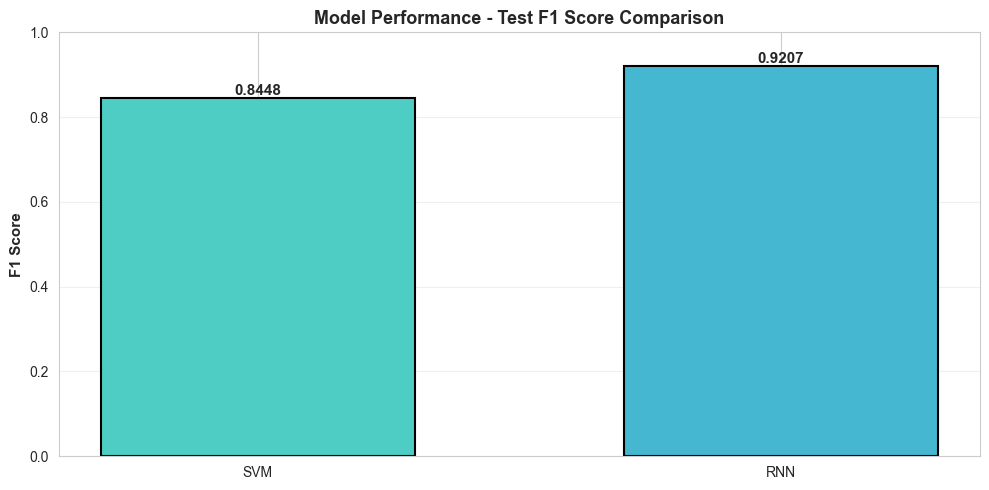


✓ Best Performing Model: RNN (F1: 0.9207)


In [13]:
# Create comparison metrics
comparison_data = []

# SVM metrics
svm_f1 = svm_results.get('test_f1', 0)
comparison_data.append({
    'Model': 'SVM',
    'F1 Score': svm_f1,
    'Accuracy': svm_results.get('test_accuracy', 0)
})

# RNN metrics
rnn_f1 = rnn_results.get('final_test_f1', 0)
comparison_data.append({
    'Model': 'RNN',
    'F1 Score': rnn_f1,
    'Accuracy': 'N/A'
})

comparison_df = pd.DataFrame(comparison_data)
print("\nModel Performance Comparison:")
print(comparison_df.to_string(index=False))

# Visualize comparison
fig, ax = plt.subplots(figsize=(10, 5))
models = comparison_df['Model'].tolist()
f1_scores = comparison_df['F1 Score'].tolist()

bars = ax.bar(models, f1_scores, color=['#4ECDC4', '#45B7D1'], width=0.6, edgecolor='black', linewidth=1.5)

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{height:.4f}',
            ha='center', va='bottom', fontweight='bold', fontsize=11)

ax.set_ylabel('F1 Score', fontsize=11, fontweight='bold')
ax.set_title('Model Performance - Test F1 Score Comparison', fontsize=13, fontweight='bold')
ax.set_ylim([0, 1])
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Determine best model
best_model = comparison_df.loc[comparison_df['F1 Score'].idxmax()]
print(f"\n✓ Best Performing Model: {best_model['Model']} (F1: {best_model['F1 Score']:.4f})")

## Model Comparison

Compare the performance of different classification approaches in Stage A.

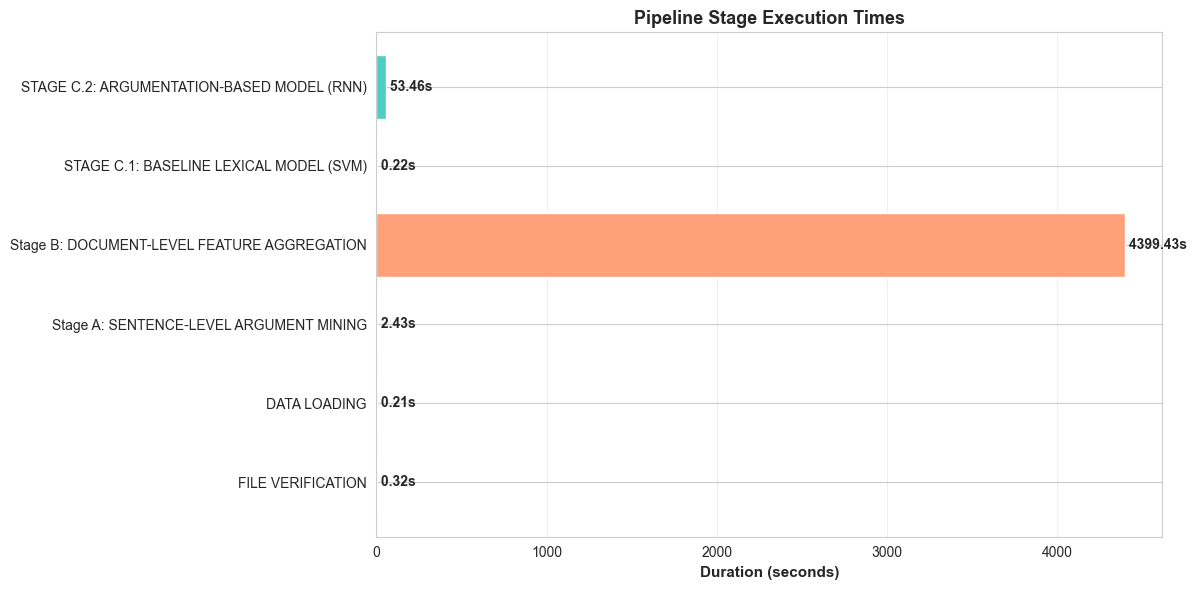

In [12]:
# Visualize pipeline timing
fig, ax = plt.subplots(figsize=(12, 6))

stage_names = []
durations = []
for stage in trace_report['stages']:
    stage_names.append(stage['stage_name'].replace('STAGE A: ', 'Stage A: ').replace('STAGE B: ', 'Stage B: '))
    durations.append(stage['elapsed_seconds'])

colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A']
bars = ax.barh(stage_names, durations, color=colors[:len(stage_names)])

# Add value labels
for i, (name, duration) in enumerate(zip(stage_names, durations)):
    ax.text(duration, i, f' {duration:.2f}s', va='center', fontweight='bold')

ax.set_xlabel('Duration (seconds)', fontsize=11, fontweight='bold')
ax.set_title('Pipeline Stage Execution Times', fontsize=13, fontweight='bold')
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

In [11]:
# Create a summary table of all pipeline stages
stages_data = []
for stage in trace_report['stages']:
    stages_data.append({
        'Stage': stage['stage_name'],
        'Duration (seconds)': f"{stage['elapsed_seconds']:.2f}",
        'Start': stage['start_timestamp'],
        'End': stage['end_timestamp']
    })

stages_df = pd.DataFrame(stages_data)
print("\nPipeline Stages Summary:")
print(stages_df.to_string(index=False))

# Total time breakdown
print("\n" + "=" * 60)
print("EXECUTION TIME BREAKDOWN")
print("=" * 60)
print(f"Total Pipeline Duration: {trace_report['total_elapsed_seconds']:.2f} seconds ({trace_report['total_elapsed_seconds']/60:.2f} minutes)")
for stage in trace_report['stages']:
    percentage = (stage['elapsed_seconds'] / trace_report['total_elapsed_seconds']) * 100
    print(f"  {stage['stage_name']}: {stage['elapsed_seconds']:.2f}s ({percentage:.1f}%)")


Pipeline Stages Summary:
                                      Stage Duration (seconds)               Start                 End
                          FILE VERIFICATION               0.32 2026-01-05 18:14:01 2026-01-05 18:14:01
                               DATA LOADING               0.21 2026-01-05 18:14:01 2026-01-05 18:14:01
    STAGE A: SENTENCE-LEVEL ARGUMENT MINING               2.43 2026-01-05 18:14:01 2026-01-05 18:14:04
STAGE B: DOCUMENT-LEVEL FEATURE AGGREGATION            4399.43 2026-01-05 18:14:04 2026-01-05 19:27:23
    STAGE C.1: BASELINE LEXICAL MODEL (SVM)               0.22 2026-01-05 19:27:23 2026-01-05 19:27:23
 STAGE C.2: ARGUMENTATION-BASED MODEL (RNN)              53.46 2026-01-05 19:27:23 2026-01-05 19:28:17

EXECUTION TIME BREAKDOWN
Total Pipeline Duration: 4456.10 seconds (74.27 minutes)
  FILE VERIFICATION: 0.32s (0.0%)
  DATA LOADING: 0.21s (0.0%)
  STAGE A: SENTENCE-LEVEL ARGUMENT MINING: 2.43s (0.1%)
  STAGE B: DOCUMENT-LEVEL FEATURE AGGREGATION: 4399

## Pipeline Summary

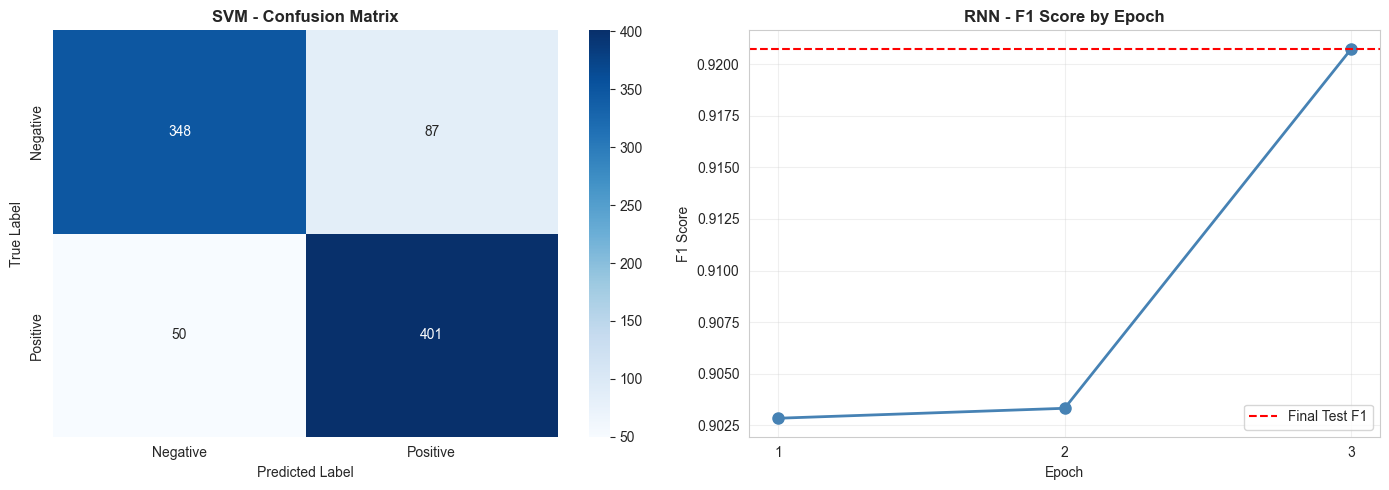

In [10]:
# Visualize Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# SVM Confusion Matrix
if 'confusion_matrix' in svm_results:
    cm_svm = np.array(svm_results['confusion_matrix'])
    sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Blues', ax=axes[0], 
                xticklabels=['Negative', 'Positive'],
                yticklabels=['Negative', 'Positive'])
    axes[0].set_title('SVM - Confusion Matrix', fontsize=12, fontweight='bold')
    axes[0].set_ylabel('True Label')
    axes[0].set_xlabel('Predicted Label')

# RNN F1 Scores over epochs
rnn_results = results.get('rnn', {})
if 'epoch_f1s' in rnn_results:
    epochs = list(range(1, len(rnn_results['epoch_f1s']) + 1))
    axes[1].plot(epochs, rnn_results['epoch_f1s'], marker='o', linewidth=2, markersize=8, color='steelblue')
    axes[1].axhline(y=rnn_results['final_test_f1'], color='r', linestyle='--', label='Final Test F1')
    axes[1].set_title('RNN - F1 Score by Epoch', fontsize=12, fontweight='bold')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('F1 Score')
    axes[1].grid(True, alpha=0.3)
    axes[1].legend()
    axes[1].set_xticks(epochs)

plt.tight_layout()
plt.show()

## Visualizations